# Credit Card Fraud Detection
**Oasis Infobyte SIP — Data Analytics L2 Task 3** · Steven Manuel Rios

Dataset: **Credit Card Fraud Detection** (ULB Machine Learning Group, Kaggle): 284,807 European card transactions over 2 days, 492 of them fraudulent. `V1`–`V28` are PCA components. The 150 MB CSV is **not committed**; the next cell downloads it from TensorFlow's public mirror if it is missing.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
import os, urllib.request
if not os.path.exists("data/creditcard.csv"):
    urllib.request.urlretrieve("https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv", "data/creditcard.csv")
df = pd.read_csv("data/creditcard.csv"); print(df.shape, "| nulls:", df.isnull().sum().sum(), "| duplicates:", df.duplicated().sum())
vc = df["Class"].value_counts(); print(vc); print(f"Fraud share: {vc[1] / len(df) * 100:.3f}%")

(284807, 31) | nulls: 0 | duplicates: 1081
Class
0    284315
1       492
Name: count, dtype: int64
Fraud share: 0.173%


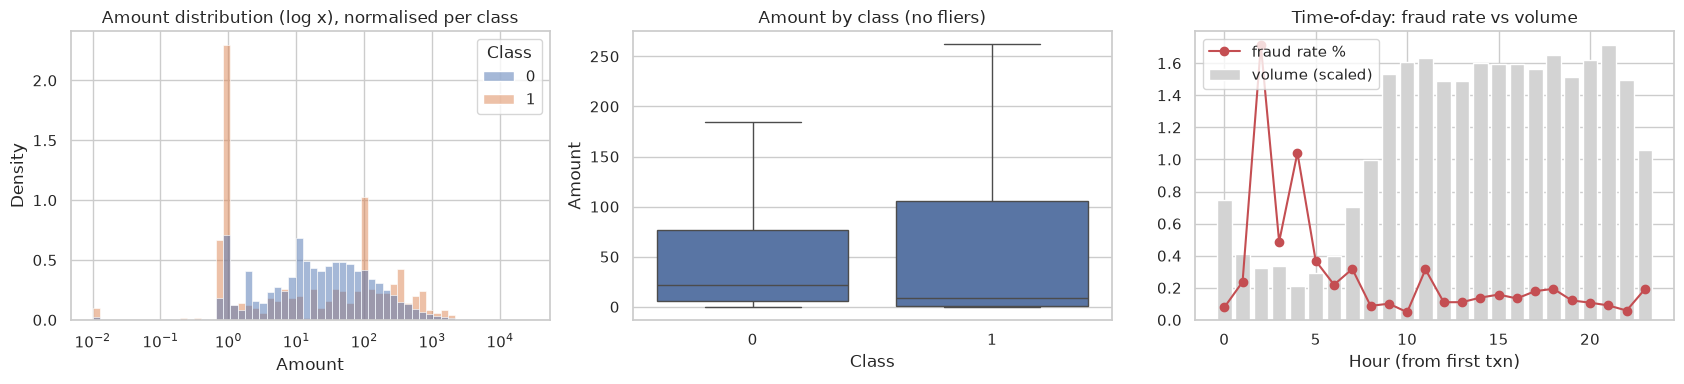

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87
Highest fraud-rate hours: {2.0: 1.713, 4.0: 1.041, 3.0: 0.487}


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(data=df, x="Amount", hue="Class", bins=60, log_scale=(True, False), stat="density", common_norm=False, ax=ax[0]); ax[0].set_title("Amount distribution (log x), normalised per class")
sns.boxplot(data=df, x="Class", y="Amount", ax=ax[1], showfliers=False); ax[1].set_title("Amount by class (no fliers)")
df["Hour"] = (df["Time"] // 3600) % 24
rate = df.groupby("Hour")["Class"].mean() * 100; cnt = df.groupby("Hour").size()
ax[2].bar(cnt.index, cnt / cnt.max() * rate.max(), color="lightgray", label="volume (scaled)"); ax[2].plot(rate.index, rate, "r-o", label="fraud rate %"); ax[2].set_title("Time-of-day: fraud rate vs volume"); ax[2].legend(); ax[2].set_xlabel("Hour (from first txn)")
save("eda"); print(df.groupby("Class")["Amount"].describe().round(2)); print("Highest fraud-rate hours:", rate.sort_values(ascending=False).head(3).round(3).to_dict())

## Why accuracy is misleading
Only **0.17%** of transactions are fraud. A model that always predicts *legitimate* scores **99.83% accuracy** while catching zero fraud. Accuracy is dominated by the majority class, so this notebook uses **precision**, **recall**, **F1**, **ROC-AUC** and **PR-AUC (average precision)**, which focus on the minority class. PR-AUC is the most informative under heavy imbalance.

In [4]:
from sklearn.model_selection import train_test_split; from sklearn.preprocessing import StandardScaler
df["logAmount"] = np.log1p(df["Amount"])
X = df.drop(columns=["Class", "Time", "Amount"]); y = df["Class"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
print("fraud in train:", ytr.sum(), "| fraud in test:", yte.sum())

fraud in train: 394 | fraud in test: 98


## Handling imbalance
* **Logistic Regression + SMOTE**: synthetic minority oversampling, applied **only to the training split** inside an imbalanced-learn pipeline so no synthetic points leak into the test set.
* **Random Forest + `class_weight='balanced_subsample'`**: re-weights the classes inside each bootstrap sample. This is cheaper than oversampling 227k rows.

In [5]:
from imblearn.pipeline import make_pipeline; from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression; from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay, confusion_matrix, precision_recall_fscore_support
models = {"LogReg + SMOTE": make_pipeline(StandardScaler(), SMOTE(random_state=42), LogisticRegression(max_iter=2000)),
          "Random Forest (balanced)": RandomForestClassifier(200, class_weight="balanced_subsample", min_samples_leaf=2, n_jobs=-1, random_state=42)}
rows = {}; proba = {}
for n, m in models.items():
    m.fit(Xtr, ytr); s = m.predict_proba(Xte)[:, 1]; p = (s >= .5).astype(int); proba[n] = s
    pr, rc, f1, _ = precision_recall_fscore_support(yte, p, average="binary")
    rows[n] = {"precision": pr, "recall": rc, "F1": f1, "ROC-AUC": roc_auc_score(yte, s), "PR-AUC": average_precision_score(yte, s), "accuracy": (p == yte).mean()}
    print(f"===== {n} =====\n", classification_report(yte, p, digits=4), "\nconfusion:\n", confusion_matrix(yte, p))
pd.DataFrame(rows).T.round(4)

===== LogReg + SMOTE =====
               precision    recall  f1-score   support

           0     0.9999    0.9723    0.9859     56864
           1     0.0540    0.9184    0.1020        98

    accuracy                         0.9722     56962
   macro avg     0.5269    0.9453    0.5440     56962
weighted avg     0.9982    0.9722    0.9844     56962
 
confusion:
 [[55288  1576]
 [    8    90]]


===== Random Forest (balanced) =====
               precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56864
           1     0.9500    0.7755    0.8539        98

    accuracy                         0.9995     56962
   macro avg     0.9748    0.8877    0.9269     56962
weighted avg     0.9995    0.9995    0.9995     56962
 
confusion:
 [[56860     4]
 [   22    76]]


,precision,recall,F1,ROC-AUC,PR-AUC,accuracy
LogReg + SMOTE,0.054,0.9184,0.1020,0.9709,0.7186,0.9722
Random Forest (balanced),0.950,0.7755,0.8539,0.9515,0.8623,0.9995


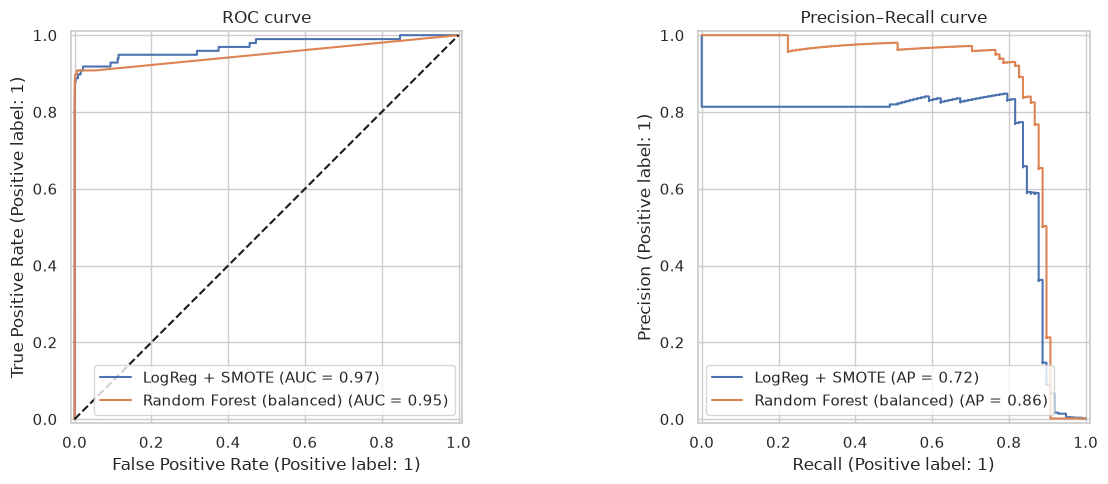

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, s in proba.items(): RocCurveDisplay.from_predictions(yte, s, name=n, ax=ax[0]); PrecisionRecallDisplay.from_predictions(yte, s, name=n, ax=ax[1])
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curve"); ax[1].set_title("Precision–Recall curve"); save("roc_pr_curves")

## Which metric matters most?
**Recall** is usually the priority, because a missed fraud (false negative) costs the full transaction amount plus chargeback fees and customer trust. A false positive costs a declined card or a verification SMS. Precision still matters: very low precision floods analysts and annoys customers. In practice a bank picks a **decision threshold** on the PR curve that meets a target such as "≥ 85% recall at an alert volume the fraud team can handle". The threshold sweep below shows the trade-off for the Random Forest.

In [7]:
s = proba["Random Forest (balanced)"]; sweep = []
for t in [.1, .2, .3, .4, .5, .6, .7]:
    p = (s >= t).astype(int); pr, rc, f1, _ = precision_recall_fscore_support(yte, p, average="binary", zero_division=0); sweep.append({"threshold": t, "precision": pr, "recall": rc, "F1": f1, "alerts": int(p.sum())})
pd.DataFrame(sweep).round(3)

,threshold,precision,recall,F1,alerts
0,0.1,0.699,0.878,0.778,123
1,0.2,0.810,0.867,0.837,105
2,0.3,0.863,0.837,0.850,95
3,0.4,0.920,0.816,0.865,87
4,0.5,0.950,0.776,0.854,80
5,0.6,0.961,0.755,0.846,77
6,0.7,0.971,0.694,0.810,70


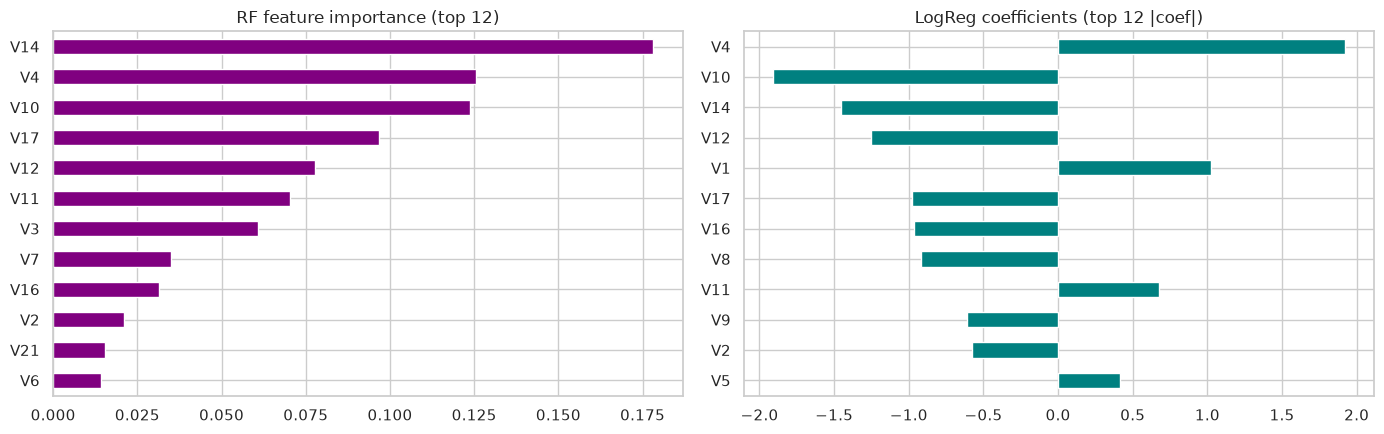

V14    0.1781
V4     0.1257
V10    0.1237
V17    0.0967
V12    0.0779
V11    0.0702
V3     0.0609
V7     0.0350
dtype: float64

In [8]:
rf = models["Random Forest (balanced)"]; imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
lr_coef = pd.Series(models["LogReg + SMOTE"][-1].coef_[0], index=X.columns)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5)); imp.head(12)[::-1].plot.barh(ax=ax[0], color="purple"); ax[0].set_title("RF feature importance (top 12)")
lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index[:12])[::-1].plot.barh(ax=ax[1], color="teal"); ax[1].set_title("LogReg coefficients (top 12 |coef|)")
save("feature_importance"); imp.head(8).round(4)

## Results & discussion
| | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| LogReg + SMOTE | 0.054 | **0.918** | 0.102 | **0.971** | 0.719 |
| Random Forest (balanced) | **0.950** | 0.776 | **0.854** | 0.952 | **0.862** |

* Both models reach **≥ 97% accuracy**, which confirms that accuracy says nothing here.
* SMOTE + LogReg catches 90 of the 98 frauds but raises **1,576 false alarms** (precision 5%), which is unusable for a fraud team.
* The Random Forest catches 76 of 98 with only **4 false alarms**. Lowering its threshold to **0.3** gives **84% recall at 86% precision** (95 alerts for 98 actual frauds). That is the best operating point in the sweep and is the recommended deployment.
* EDA: fraud amounts have a *lower median* (\$9 vs \$22) but a heavier upper tail. The fraud rate spikes in the night hours (hours 2–4 of the cycle), when legitimate volume is lowest.
* Top features are **V14, V4, V10, V17 and V12**, consistent across the RF importances and the LogReg coefficients.

## Scalability: 1 million transactions per hour
That is about 280 transactions per second.
* **Inference cost:** a 200-tree forest scores roughly 10⁴–10⁵ rows per second per core in batch mode, so one container can handle the load. For single-transaction scoring at low latency, export the model (ONNX or Treelite) behind a stateless REST/gRPC service and scale it horizontally.
* **Streaming:** consume a Kafka stream of transactions and compute features (velocity, merchant history) in a stream processor such as Flink or Spark Structured Streaming with a low-latency feature store like Redis. The model outputs a score, and a **threshold or rules layer** decides whether to approve, challenge (OTP) or block.
* **Training:** retrain periodically on the latest labelled chargebacks to handle concept drift, and monitor PR-AUC and alert volume. Gradient-boosted trees (XGBoost/LightGBM) are more memory-efficient at this scale.